# 01 · Análisis exploratorio de datos (EDA)
**Proyecto integrador — Lector de Facturas** · Sebastián Rojas y Jesús López

Este notebook explora los datos con los que se desarrolló y evaluó el lector: **SROIE** (recibos escaneados) y **WildReceipt** (recibos fotografiados). Responde tres preguntas:

1. ¿Qué datos tenemos y cómo se reparten entre entrenamiento, validación y test?
2. ¿Qué campos se pueden evaluar con cada dataset?
3. ¿Qué características de las imágenes y de las etiquetas deberían guiar el preprocesamiento y el modelo?

> **Regla:** el análisis usa solo **train y validation**. Del test oficial se revisan integridad y duplicados, nunca sus etiquetas.

Los resultados se discuten en [`docs/analisis_datos.md`](../docs/analisis_datos.md). Las funciones de gráficos están en la sección 1 (se repiten en cada notebook para que funcione solo en Colab). Las figuras finales se copian a [`results/figures/eda/`](../results/figures/eda/).

**Contenido:** 1. Configuración · 2. Partición y control de fugas · 3. EDA del proyecto · 4. Ejemplos visuales · 5. Estadísticas descriptivas · 6. Visualizaciones · 7. Patrones en las etiquetas · 8. Outliers e incidencias · 9. Conclusiones

## 1. Configuración

In [ ]:
# ===== Configuración común de los notebooks 01–06 =====
# En Colab no hace falta clonar nada: se descarga el código de GitHub y se registra su commit.
USAR_CODIGO_LOCAL = False  # True si abres Jupyter dentro de un clon local del repositorio
CODIGO_LOCAL = ''          # Opcional: ruta del clon local (por defecto, la carpeta padre de notebooks/)
USAR_DRIVE = False         # True: datos, pesos, caché OCR y resultados quedan en Google Drive (los notebooks no repiten descargas ni OCR)
DESCARGAR_SI_FALTAN = True
DATOS_MANUAL = ''          # Opcional: ruta a data/raw existente en Drive o Colab
REPOSITORIO = 'Jesusl2202/Document-Scanner'
RAMA = 'main'
SEED = 42

from pathlib import Path
import os, sys, json, subprocess, shutil, hashlib, zipfile, io, urllib.request


def comando(args, cwd=None, mostrar_error=True):
    """Ejecuta un comando y muestra la salida solo si falla."""
    r = subprocess.run(list(map(str, args)), cwd=cwd, capture_output=True, text=True)
    if r.returncode:
        if mostrar_error:
            print(r.stdout[-3000:]); print(r.stderr[-3000:])
        r.check_returncode()
    return r.stdout + r.stderr


# 1) Carpeta de trabajo (fuera de Git)
if USAR_CODIGO_LOCAL:
    CODIGO = Path(CODIGO_LOCAL) if CODIGO_LOCAL else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
    TRABAJO = CODIGO / 'outputs/experimentos'
elif USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    TRABAJO = Path('/content/drive/MyDrive/Lector_Facturas_Experimentos')
else:
    TRABAJO = Path('/content/Lector_Facturas_Experimentos')
TRABAJO.mkdir(parents=True, exist_ok=True)
SALIDAS = TRABAJO / 'notebooks'
SALIDAS.mkdir(parents=True, exist_ok=True)

# 2) Código del repositorio: se descarga el commit exacto y se registra
if USAR_CODIGO_LOCAL:
    REVISION = {'modo': 'local', 'ruta': str(CODIGO)}
else:
    pedido = urllib.request.Request(f'https://api.github.com/repos/{REPOSITORIO}/commits/{RAMA}', headers={'User-Agent': 'lector-facturas'})
    with urllib.request.urlopen(pedido, timeout=60) as respuesta:
        commit = json.load(respuesta)['sha']
    CODIGO = TRABAJO / f'codigo_{commit[:7]}'
    if not (CODIGO / 'src/lector_facturas/consensus.py').exists():
        with urllib.request.urlopen(f'https://codeload.github.com/{REPOSITORIO}/zip/{commit}', timeout=120) as respuesta:
            blob = respuesta.read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            for nombre in z.namelist():
                relativo = '/'.join(nombre.split('/')[1:])
                if not relativo or nombre.endswith('/'):
                    continue
                destino = (CODIGO / relativo).resolve()
                if not destino.is_relative_to(CODIGO.resolve()):
                    raise ValueError('Ruta no permitida dentro del ZIP')
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(z.read(nombre))
    REVISION = {'repositorio': REPOSITORIO, 'rama': RAMA, 'commit': commit}
assert (CODIGO / 'src/lector_facturas/consensus.py').exists(), 'No se encontró el código del lector.'
RAIZ = CODIGO
print('Código:', REVISION)

# 3) Tesseract y bibliotecas
if shutil.which('apt-get') and not shutil.which('tesseract'):
    print('Instalando Tesseract...')
    comando(['apt-get', 'update', '-qq'])
    comando(['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'])
assert shutil.which('tesseract'), 'No se encontró Tesseract. Usa Google Colab con CPU o instálalo en tu equipo.'
comando([sys.executable, '-m', 'pip', 'install', '-q', '-r', CODIGO / 'requirements.txt'])
sys.path.insert(0, str(CODIGO / 'src'))
for modulo in list(sys.modules):
    if modulo == 'lector_facturas' or modulo.startswith('lector_facturas.'):
        del sys.modules[modulo]

# 4) Modelo: configuración definitiva + pesos Tesseract fijados por SHA-256 (fast, best y español)
from lector_facturas import frozen_runtime
RAW_CONFIG = json.loads((CODIGO / 'configs/definitivo.json').read_text(encoding='utf-8'))
assert hasattr(frozen_runtime, 'bind_models') and RAW_CONFIG.get('observed_accounting'), (
    'El código descargado no corresponde al modelo «resumen contable» (configs/definitivo.json). '
    'Revisa REPOSITORIO y RAMA, o usa USAR_CODIGO_LOCAL=True dentro de un clon del repositorio.')
RAW_CONFIG['seed'] = SEED
CONFIG = frozen_runtime.bind_models(RAW_CONFIG, TRABAJO / 'modelos')
VISTAS_MODELO = len(CONFIG['ocr']['ensemble_views'])
print(comando(['tesseract', '--version']).splitlines()[0], f'| {VISTAS_MODELO} vistas OCR + hasta',
      CONFIG['ocr']['adaptive_rescue']['max_views'], 'de rescate')

# 5) Datos: se buscan por contenido y se descargan si faltan
candidatos = [Path(DATOS_MANUAL)] if DATOS_MANUAL else [
    Path('/content/Document-Scanner/data/raw'), TRABAJO / 'data/raw']
DATOS = next((p for p in candidatos if p.exists()), candidatos[-1])
DATOS.mkdir(parents=True, exist_ok=True)


def localizar():
    """Encuentra la raíz de SROIE y de WildReceipt por su contenido, no por el nombre de la carpeta."""
    sroie = next((p.parent.parent for p in DATOS.rglob('entities') if p.is_dir() and p.parent.name == 'train'
                  and (p.parent / 'img').exists() and (p.parent / 'box').exists()), None)
    wild = next((p.parent for p in DATOS.rglob('class_list.txt') if (p.parent / 'train.txt').exists() and (p.parent / 'test.txt').exists()), None)
    return sroie, wild


SROIE, WILD = localizar()
for nombre, ruta in [('sroie', SROIE), ('wildreceipt', WILD)]:
    if ruta is None and DESCARGAR_SI_FALTAN:
        print('Descargando', nombre, '...', flush=True)
        try:
            print(comando([sys.executable, CODIGO / 'scripts/download_data.py', nombre, '--out', DATOS], mostrar_error=False))
        except subprocess.CalledProcessError:
            print(f'No se pudo descargar {nombre}. Descárgalo a mano en {DATOS} o indica DATOS_MANUAL (ver data/raw/README.md).')
SROIE, WILD = localizar()
print('SROIE:      ', SROIE or 'NO ENCONTRADO')
print('WildReceipt:', WILD or 'NO ENCONTRADO')
assert SROIE and WILD, 'Faltan datasets: revisa data/raw/README.md.'

# 6) Manifiesto con la partición del proyecto (train / validation / test / quarantine)
from lector_facturas.datasets import prepare
FILAS = prepare(SROIE, WILD, SALIDAS / 'preparados', RAW_CONFIG)
REVISADOS = json.loads((CODIGO / 'configs/documentos_revisados.json').read_text(encoding='utf-8'))
print('Documentos en el manifiesto:', len(FILAS), '| documentos ya revisados en el desarrollo:', len(REVISADOS))

In [2]:
# Funciones de gráficos compartidas por los notebooks 01–06 (se repiten para que cada uno funcione solo en Colab).
import glob, re, json, types
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

FONDO, TEXTO, TEXTO2, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

COLOR = {'sroie': AZUL, 'wildreceipt': NARANJA}

NOMBRE = {'sroie': 'SROIE', 'wildreceipt': 'WildReceipt'}

CAMPOS = ['tax_id', 'date', 'document_number', 'subtotal', 'tax', 'total']

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'axes.edgecolor': REJILLA,
    'axes.labelcolor': TEXTO2, 'xtick.color': TEXTO2, 'ytick.color': TEXTO2, 'text.color': TEXTO,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': REJILLA, 'grid.linewidth': .6, 'axes.axisbelow': True, 'legend.frameon': False})

def es_num(valor, decimales=0):
    """Formato numérico en español: 1.234,5."""
    texto = f'{valor:,.{decimales}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')

def guardar(fig, carpeta, nombre):
    fig.tight_layout()
    fig.savefig(Path(carpeta) / nombre, dpi=150)
    plt.close(fig)
    print('  figura:', nombre)

def leer_csv(ruta):
    return pd.read_csv(ruta, encoding='utf-8-sig')

def fig_particiones(documentos, incidencias, manifest, salida):
    """Figura 1. Documentos por partición y dataset."""
    if manifest is not None:
        conteo = manifest.groupby(['dataset', 'split']).size().unstack(fill_value=0)
    else:
        # Sin manifiesto solo se conocen desarrollo y cuarentena.
        conteo = documentos.groupby(['dataset', 'split']).size().unstack(fill_value=0)
        cuarentena = incidencias[incidencias.split == 'quarantine'].drop_duplicates('id')
        conteo['quarantine'] = cuarentena.groupby('dataset').size().reindex(conteo.index, fill_value=0)
        print('  aviso: sin --manifest la Figura 1 no muestra el test oficial')
    columnas = {'train': ('Entrenamiento', AZUL), 'validation': ('Validación', AQUA),
                'test': ('Test oficial (reservado)', GRIS), 'quarantine': ('Cuarentena', NARANJA)}
    total = int(conteo.values.sum())
    fig, ax = plt.subplots(figsize=(8, 3.2))
    izquierda = np.zeros(len(conteo))
    etiquetas = [NOMBRE.get(d, d) for d in conteo.index]
    for clave, (texto, color) in columnas.items():
        if clave not in conteo:
            continue
        valores = conteo[clave].values
        ax.barh(etiquetas, valores, left=izquierda, color=color, label=texto,
                edgecolor=FONDO, linewidth=2, height=.55)
        for i, v in enumerate(valores):
            if v > 60:
                ax.text(izquierda[i] + v / 2, i, es_num(v), ha='center', va='center',
                        color='white', fontsize=9, fontweight='bold')
        izquierda += valores
    ax.set_xlabel('Documentos')
    ax.set_title(f'Figura 1. Partición de los {es_num(total)} documentos', loc='left')
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.28))
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()
    guardar(fig, salida, '01_particiones.png')
    return conteo

def fig_resolucion(documentos, salida):
    """Figura 2. Ancho vs. alto de las imágenes de desarrollo."""
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for ds in ['wildreceipt', 'sroie']:
        g = documentos[documentos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.width, g.height, s=12, alpha=.45, color=COLOR[ds], edgecolors='none',
                   label=f'{NOMBRE[ds]} (mediana {int(g.width.median())}×{int(g.height.median())} px)')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Ancho (px, escala log)')
    ax.set_ylabel('Alto (px, escala log)')
    ax.set_title('Figura 2. Resolución de las imágenes de desarrollo', loc='left')
    ax.legend(loc='upper left')
    guardar(fig, salida, '02_resolucion.png')

def fig_regiones(documentos, salida):
    """Figura 3. Regiones de texto anotadas por documento."""
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    bins = np.arange(0, documentos.regions.max() + 6, 6)
    for ds in ['sroie', 'wildreceipt']:
        g = documentos[documentos.dataset == ds].regions
        if g.empty:
            continue
        ax.hist(g, bins=bins, alpha=.6, color=COLOR[ds], edgecolor=FONDO, linewidth=1,
                label=f'{NOMBRE[ds]} (mediana {int(g.median())})')
        ax.axvline(g.median(), color=COLOR[ds], ls='--', lw=1.5)
    ax.set_xlabel('Regiones de texto anotadas por documento')
    ax.set_ylabel('Documentos')
    ax.set_title('Figura 3. Cantidad de texto por recibo', loc='left')
    ax.legend()
    guardar(fig, salida, '03_regiones.png')

def fig_cobertura(cobertura, salida):
    """Figura 4. Porcentaje de documentos con etiqueta utilizable por campo."""
    tabla = cobertura.pivot(index='dataset', columns='field', values='coverage').reindex(columns=CAMPOS)
    mapa = LinearSegmentedColormap.from_list('azules', ['#f1f0ec', '#cfe0f6', '#7fb0ea', AZUL, '#0d3f80'])
    fig, ax = plt.subplots(figsize=(8, 1.3 + .65 * len(tabla)))
    ax.imshow(tabla.values, cmap=mapa, vmin=0, vmax=1, aspect='auto')
    ax.grid(False)
    ax.set_xticks(range(len(CAMPOS)), CAMPOS)
    ax.set_yticks(range(len(tabla)), [NOMBRE.get(d, d) for d in tabla.index])
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            ax.text(j, i, f'{es_num(100 * v)}%', ha='center', va='center',
                    color='white' if v > .55 else TEXTO, fontweight='bold')
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.set_title('Figura 4. Campos con etiqueta utilizable (documentos de desarrollo)', loc='left')
    guardar(fig, salida, '04_cobertura.png')

def fig_clases_lineas(texto, salida):
    """Figura 5. Desbalance de clases por línea (datos del clasificador de Semana 3)."""
    conteo = pd.Series({k.strip(): int(v) for k, v in (p.split('=') for p in texto.split(','))}).sort_values()
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.barh(conteo.index, conteo.values, height=.55,
            color=[GRIS if k.lower().startswith('otro') else AZUL for k in conteo.index])
    for i, v in enumerate(conteo.values):
        ax.text(v * 1.08, i, f'{es_num(v)} ({es_num(100 * v / total, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xscale('log')
    ax.set_xlim(conteo.min() / 2, conteo.max() * 4)
    ax.set_xlabel('Líneas OCR en entrenamiento (escala log)')
    ax.grid(axis='y', visible=False)
    ax.set_title('Figura 5. Desbalance de clases por línea', loc='left')
    guardar(fig, salida, '05_desbalance_lineas.png')

def fig_cer(cer, documentos, salida):
    """Figura 6. CER del OCR frente al tamaño de la imagen."""
    datos = cer.merge(documentos, on=['id', 'dataset'])
    if datos.empty:
        print('  aviso: los documentos de cer.csv no están en documents.csv; se omite la Figura 6')
        return None
    datos['mpx'] = datos.width * datos.height / 1e6
    rho = datos[['cer', 'mpx']].corr(method='spearman').iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for ds in ['sroie', 'wildreceipt']:
        g = datos[datos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.mpx, g.cer, s=46, color=COLOR[ds], edgecolors=FONDO, linewidths=1.5,
                   label=f'{NOMBRE[ds]} (CER mediano {es_num(g.cer.median(), 2)})')
    ax.set_xscale('log')
    ax.set_xlabel('Tamaño de la imagen (megapíxeles, escala log)')
    ax.set_ylabel('CER del OCR')
    ax.set_title(f'Figura 6. Imágenes más pequeñas se leen peor (Spearman ρ = {es_num(rho, 2)})', loc='left')
    ax.legend()
    guardar(fig, salida, '06_cer_vs_resolucion.png')
    return datos

def tipo_error(errores):
    """Clasifica cada campo evaluado en correcto, omitido o valor incorrecto."""
    vacio = errores.predicted.isna() | (errores.predicted.astype(str).str.strip() == '')
    return np.where(errores.correct == 1, 'Correcto',
                    np.where(vacio, 'Omitido (no extrajo nada)', 'Valor incorrecto'))

def fig_errores(errores, salida):
    """Figura 7. Resultado por campo: correcto, valor incorrecto u omitido."""
    errores = errores.assign(tipo=tipo_error(errores))
    orden = ['Correcto', 'Valor incorrecto', 'Omitido (no extrajo nada)']
    tabla = errores.groupby(['dataset', 'field', 'tipo']).size().unstack(fill_value=0).reindex(columns=orden, fill_value=0)
    tabla.index = [f'{NOMBRE.get(d, d)} · {c}' for d, c in tabla.index]
    documentos = errores.id.nunique()
    fig, ax = plt.subplots(figsize=(8, 1.4 + .4 * len(tabla)))
    izquierda = np.zeros(len(tabla))
    for col, color in zip(orden, [AQUA, NARANJA, '#b9b8b2']):
        valores = tabla[col].values
        ax.barh(tabla.index, valores, left=izquierda, color=color, label=col, edgecolor=FONDO, linewidth=2, height=.6)
        for i, v in enumerate(valores):
            if v >= 2:
                ax.text(izquierda[i] + v / 2, i, str(v), ha='center', va='center', fontsize=9,
                        color=TEXTO if col.startswith('Omitido') else 'white')
        izquierda += valores
    ax.invert_yaxis()
    ax.set_xlabel('Campos anotados')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'Figura 7. Resultado por campo ({documentos} documentos)', loc='left')
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.2))
    guardar(fig, salida, '07_errores_linea_base.png')
    return errores

def fig_correlaciones(documentos, salida):
    """Figura 8. Correlación de Spearman entre variables de la imagen, por dataset."""
    variables = {'width': 'Ancho', 'height': 'Alto', 'mpx': 'Megapíxeles', 'regions': 'Regiones', 'aspect': 'Alto/ancho'}
    mapa = LinearSegmentedColormap.from_list('div', [NARANJA, '#f6c3ad', '#f1f0ec', '#a9c8f0', AZUL])
    bases = [d for d in ['sroie', 'wildreceipt'] if d in set(documentos.dataset)]
    fig, ejes = plt.subplots(1, len(bases), figsize=(4.5 * len(bases), 3.8), squeeze=False)
    matrices = {}
    for ax, ds in zip(ejes[0], bases):
        m = documentos[documentos.dataset == ds][list(variables)].corr(method='spearman')
        matrices[ds] = m
        ax.imshow(m.values, cmap=mapa, vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(len(variables)), variables.values(), rotation=35, ha='right')
        ax.set_yticks(range(len(variables)), variables.values())
        for i in range(len(variables)):
            for j in range(len(variables)):
                v = m.values[i, j]
                ax.text(j, i, es_num(v, 2), ha='center', va='center', fontsize=8,
                        color='white' if abs(v) > .6 else TEXTO)
        ax.set_title(NOMBRE[ds])
        for borde in ax.spines.values():
            borde.set_visible(False)
    fig.suptitle('Figura 8. Correlación de Spearman entre variables de la imagen', x=.02, ha='left', fontweight='bold')
    guardar(fig, salida, '08_correlaciones.png')
    return matrices

PATRONES_FECHA = {'99/99/9999': 'dd/mm/aaaa', '99-99-99': 'dd-mm-aa', '99-99-9999': 'dd-mm-aaaa',
                  '99/99/99': 'dd/mm/aa', '99 A 9999': 'dd MES aaaa'}

def patron(fecha):
    """Convierte '25/12/2018' en '99/99/9999' y 'MAR' en 'A' para agrupar formatos."""
    return re.sub(r'\d', '9', re.sub(r'[A-Za-z]+', 'A', fecha))

def fig_formatos_fecha(carpeta, salida):
    """Figura 9. Formatos de fecha en las etiquetas de entrenamiento de SROIE."""
    fechas = []
    for archivo in sorted(glob.glob(str(Path(carpeta) / '*'))):
        if not archivo.endswith(('.json', '.txt')):
            continue
        try:
            fechas.append(str(json.loads(Path(archivo).read_text(encoding='utf-8-sig')).get('date', '')).strip())
        except (json.JSONDecodeError, UnicodeDecodeError):
            print('  aviso: no se pudo leer', archivo)
    if not fechas:
        print('  aviso: no hay etiquetas en --sroie-keys; se omite la Figura 9')
        return None
    formatos = Counter(patron(f) for f in fechas)
    ambiguas = 0
    for f in fechas:
        m = re.fullmatch(r'\(?(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})\)?', f)
        if m and int(m.group(1)) <= 12 and int(m.group(2)) <= 12 and m.group(1) != m.group(2):
            ambiguas += 1
    agrupado = Counter()
    for p, n in formatos.items():
        agrupado[PATRONES_FECHA.get(p, 'otros')] += n
    otros = len([p for p in formatos if p not in PATRONES_FECHA])
    orden = [v for v in PATRONES_FECHA.values() if agrupado[v]] + (['otros'] if agrupado['otros'] else [])
    orden = orden[::-1]
    etiquetas = [f'Otros {otros} formatos' if o == 'otros' else o for o in orden]
    valores = [agrupado[o] for o in orden]
    n = len(fechas)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh(etiquetas, valores, color=AZUL, height=.55)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(valores):
        ax.text(v + n * .006, i, f'{v} ({es_num(100 * v / n, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xlim(0, max(valores) * 1.2)
    ax.set_xlabel(f'Recibos de entrenamiento de SROIE (n = {n})')
    ax.set_title('Figura 9. Formatos de fecha en las etiquetas de SROIE', loc='left')
    guardar(fig, salida, '09_formatos_fecha.png')
    return {'recibos': n, 'formatos_distintos': len(formatos), 'fechas_dia_mes_ambiguas': ambiguas,
            'porcentaje_ambiguas': round(100 * ambiguas / n, 1),
            'formatos': dict(formatos.most_common())}

def tablas(documentos, salida):
    """Estadísticas descriptivas y outliers (criterio 1,5 × IQR) por dataset."""
    variables = ['width', 'height', 'aspect', 'mpx', 'regions']
    describe = documentos.groupby('dataset')[variables].describe(percentiles=[.25, .5, .75]).T.round(2)
    describe.to_csv(Path(salida) / 'estadisticas_descriptivas.csv', encoding='utf-8-sig')
    filas = []
    for ds, g in documentos.groupby('dataset'):
        for v in ['width', 'height', 'mpx', 'regions']:
            q1, q3 = g[v].quantile([.25, .75])
            limite_bajo, limite_alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
            n = int(((g[v] < limite_bajo) | (g[v] > limite_alto)).sum())
            filas.append({'dataset': ds, 'variable': v, 'outliers': n, 'documentos': len(g),
                          'porcentaje': round(100 * n / len(g), 1),
                          'limite_inferior': round(limite_bajo, 2), 'limite_superior': round(limite_alto, 2)})
    outliers = pd.DataFrame(filas)
    outliers.to_csv(Path(salida) / 'outliers_iqr.csv', index=False, encoding='utf-8-sig')
    print('  tablas: estadisticas_descriptivas.csv, outliers_iqr.csv')
    return describe, outliers

F = types.SimpleNamespace(AZUL=AZUL, NARANJA=NARANJA, AQUA=AQUA, GRIS=GRIS, FONDO=FONDO, TEXTO=TEXTO, TEXTO2=TEXTO2, REJILLA=REJILLA, COLOR=COLOR, NOMBRE=NOMBRE, CAMPOS=CAMPOS, es_num=es_num, guardar=guardar, leer_csv=leer_csv, fig_particiones=fig_particiones, fig_resolucion=fig_resolucion, fig_regiones=fig_regiones, fig_cobertura=fig_cobertura, fig_clases_lineas=fig_clases_lineas, fig_cer=fig_cer, tipo_error=tipo_error, fig_errores=fig_errores, fig_correlaciones=fig_correlaciones, PATRONES_FECHA=PATRONES_FECHA, patron=patron, fig_formatos_fecha=fig_formatos_fecha, tablas=tablas)

In [ ]:
import json, re, hashlib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as Img, Markdown
warnings.filterwarnings('ignore', category=FutureWarning)
%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
FIG = SALIDAS / 'figuras_eda'   # las figuras del repositorio están en results/figures/eda
FIG.mkdir(parents=True, exist_ok=True)
print('Figuras en:', FIG)

## 2. Partición y control de fugas
`prepare()` asigna cada documento a una partición:
- **test**: test oficial del dataset, reservado.
- **validation**: ~20 % del entrenamiento oficial, por hash de la imagen con semilla 42.
- **train**: el resto.
- **quarantine**: imágenes duplicadas o que también están en el test oficial.

In [3]:
manifest = pd.DataFrame([{
    'id': r['id'], 'dataset': r['dataset'], 'source_split': r['source_split'], 'split': r['split'],
    'sha256': r.get('sha256'), 'width': r.get('width'), 'height': r.get('height'),
    'regions': len(r['regions']), 'issues': ';'.join(r['issues'])} for r in FILAS])
tabla = pd.crosstab(manifest.dataset, manifest.split, margins=True, margins_name='Total')
display(tabla)

split,quarantine,test,train,validation,Total
dataset,,,,,
sroie,15,344,501,113,973
wildreceipt,0,472,1016,251,1739
Total,15,816,1517,364,2712


In [4]:
# Control de fugas: ninguna imagen (por SHA-256) puede estar en dos particiones utilizables.
particiones = {s: set(manifest.loc[manifest.split == s, 'sha256'].dropna()) for s in ['train', 'validation', 'test']}
cruces = pd.DataFrame([{'partición A': a, 'partición B': b, 'imágenes compartidas': len(particiones[a] & particiones[b])}
                       for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]])
display(cruces)
assert cruces['imágenes compartidas'].sum() == 0, 'Hay fuga de datos entre particiones'
print('Sin fugas entre train, validation y test.')

,partición A,partición B,imágenes compartidas
0,train,validation,0
1,train,test,0
2,validation,test,0


Sin fugas entre train, validation y test.


## 3. EDA del proyecto (`run_eda`)
`run_eda` genera el inventario de desarrollo (`documents.csv`), la cobertura de etiquetas por campo (`coverage.csv`) y las incidencias (`incidents.csv`). Del test solo inventaría integridad.

In [5]:
from lector_facturas.eda import run_eda
EDA = SALIDAS / 'eda'
resumen = run_eda(FILAS, EDA)
%matplotlib inline
documentos = pd.read_csv(EDA / 'documents.csv', encoding='utf-8-sig')
cobertura = pd.read_csv(EDA / 'coverage.csv', encoding='utf-8-sig')
incidencias = pd.read_csv(EDA / 'incidents.csv', encoding='utf-8-sig')
print(json.dumps({k: resumen[k] for k in ['total_manifest', 'development_documents', 'split_counts', 'datasets']}, indent=2))
display(cobertura.assign(coverage=(100 * cobertura.coverage).round(1)).rename(columns={'coverage': 'cobertura %'}))

{
  "total_manifest": 2712,
  "development_documents": 1881,
  "split_counts": {
    "train": 1517,
    "validation": 364,
    "quarantine": 15,
    "test": 816
  },
  "datasets": {
    "sroie": 614,
    "wildreceipt": 1267
  }
}


,dataset,field,documents,annotated,unannotated,ambiguous,cobertura %
0,sroie,tax_id,614,0,614,0,0.0
1,sroie,date,614,614,0,0,100.0
2,sroie,document_number,614,0,614,0,0.0
3,sroie,subtotal,614,0,614,0,0.0
4,sroie,tax,614,0,614,0,0.0
5,sroie,total,614,613,1,0,99.8
6,wildreceipt,tax_id,1267,0,1267,0,0.0
7,wildreceipt,date,1267,1025,195,47,80.9
8,wildreceipt,document_number,1267,0,1267,0,0.0
9,wildreceipt,subtotal,1267,876,374,17,69.1


## 4. Ejemplos visuales
Dos recibos de entrenamiento por dataset con sus regiones de texto. En WildReceipt se colorean las regiones etiquetadas como fecha, subtotal, impuesto y total; en SROIE (que no etiqueta regiones) se resaltan las regiones cuyo texto coincide con la fecha o el total de referencia.

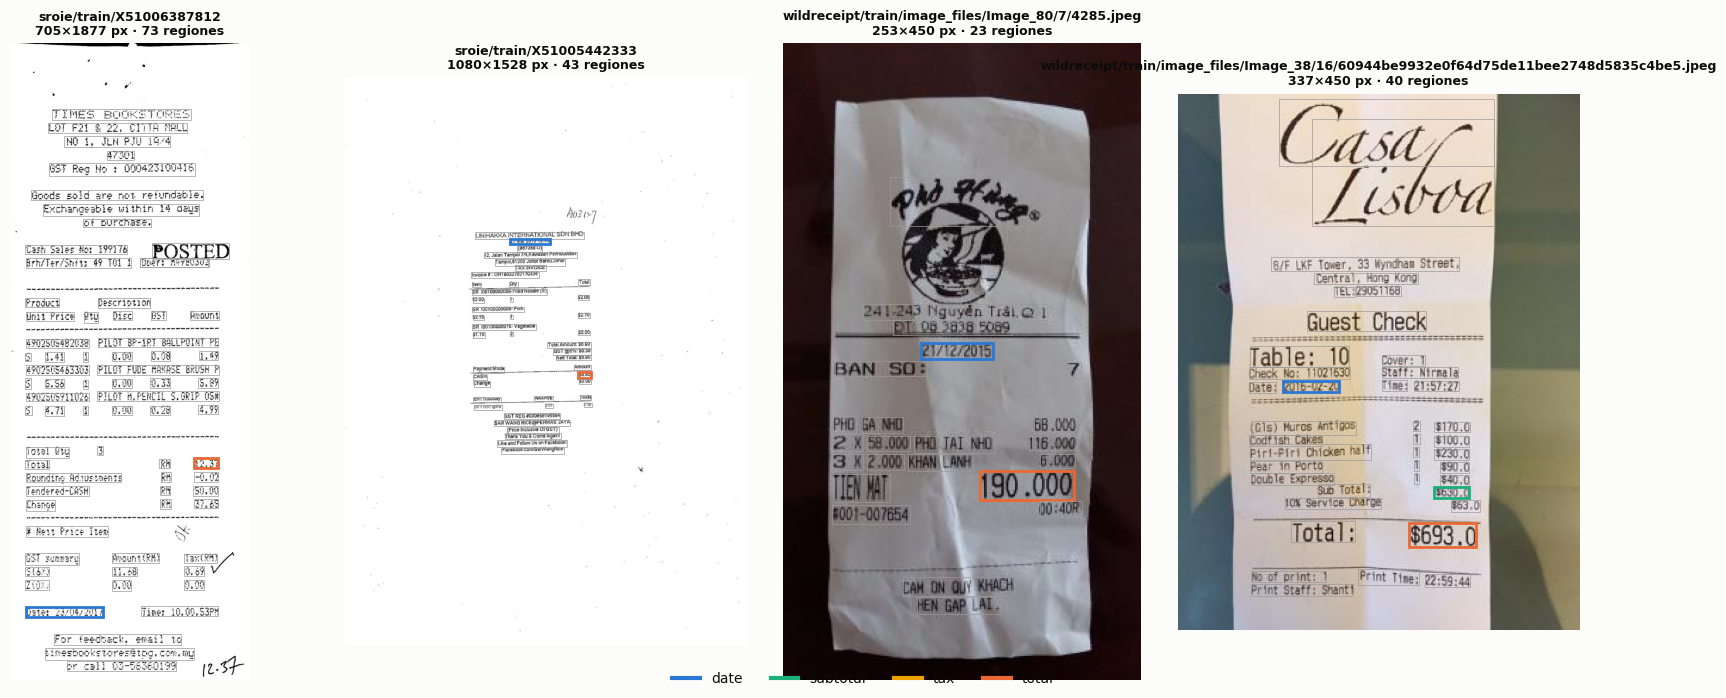

In [6]:
from PIL import Image
from matplotlib.patches import Rectangle
from lector_facturas.common import normalize

COLORES = {'date': '#2a78d6', 'subtotal': '#1baf7a', 'tax': '#eda100', 'total': '#eb6834'}
ETIQUETA_WILD = {'Date_value': 'date', 'Subtotal_value': 'subtotal', 'Tax_value': 'tax', 'Total_value': 'total'}

def campo_region(fila, region):
    """Campo al que corresponde una región (o None)."""
    if fila['dataset'] == 'wildreceipt':
        return ETIQUETA_WILD.get(region.get('label'))
    for campo in ('date', 'total'):
        oro = fila['gold'][campo]
        if oro['status'] == 'annotated' and normalize(campo, oro['value']) == normalize(campo, region['text']):
            return campo
    return None

def dibujar(fila, ax):
    with Image.open(fila['image']) as im:
        ax.imshow(im.convert('RGB'))
    for region in fila['regions']:
        x1, y1, x2, y2 = region['box']
        campo = campo_region(fila, region)
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2 if campo else .5,
                               edgecolor=COLORES.get(campo, '#9a9a9a')))
    ax.set_title(f"{fila['id']}\n{fila['width']}×{fila['height']} px · {len(fila['regions'])} regiones", fontsize=9)
    ax.axis('off')

ejemplos = []
for base in ('sroie', 'wildreceipt'):
    pool = sorted([r for r in FILAS if r['dataset'] == base and r['split'] == 'train' and r.get('width')],
                  key=lambda r: hashlib.sha256(f"{SEED}:{r['id']}".encode()).hexdigest())
    ejemplos += pool[:2]
if ejemplos:
    fig, ejes = plt.subplots(1, len(ejemplos), figsize=(4.2 * len(ejemplos), 7))
    for fila, ax in zip(ejemplos, np.atleast_1d(ejes)):
        dibujar(fila, ax)
    fig.legend(handles=[plt.Line2D([], [], color=c, lw=3, label=k) for k, c in COLORES.items()],
               loc='lower center', ncol=4, frameon=False)
    plt.tight_layout(); plt.show()

## 5. Estadísticas descriptivas
Variables de cada imagen de desarrollo: ancho, alto, megapíxeles, relación alto/ancho y número de regiones de texto anotadas.

In [7]:
documentos = documentos[documentos.width.notna()].copy()
documentos['mpx'] = documentos.width * documentos.height / 1e6
documentos['aspect'] = documentos.height / documentos.width
descriptivas = documentos.groupby('dataset')[['width', 'height', 'mpx', 'aspect', 'regions']].describe(percentiles=[.25, .5, .75])
display(descriptivas.T.round(2))

dataset          sroie  wildreceipt
width   count   614.00      1267.00
        mean   1337.69       632.90
        std    1424.90       547.58
        min     436.00       150.00
        25%     623.00       338.00
        50%     815.00       412.00
        75%     936.00       750.00
        max    4961.00      6016.00
height  count   614.00      1267.00
        mean   2373.43       819.59
        std    1854.34       713.15
        min     605.00       168.00
        25%    1399.00       450.00
        50%    1687.00       480.00
        75%    2143.00      1000.00
        max    7016.00      5312.00
mpx     count   614.00      1267.00
        mean      5.77         0.87
        std      11.31         1.99
        min       0.28         0.03
        25%       0.93         0.15
        50%       1.44         0.20
        75%       1.95         0.75
        max      34.81        24.16
aspect  count   614.00      1267.00
        mean      2.05         1.32
        std       0.49         0.36
        min       1.03         0.42
        25%       1.71         1.00
        50%       1.99         1.33
        75%       2.36         1.34
        max       3.80         3.93
regions count   614.00      1267.00
        mean     53.81        42.00
        std      18.01        20.28
        min      18.00        12.00
        25%      42.00        30.00
        50%      50.00        38.00
        75%      63.00        48.00
        max     153.00       234.00

## 6. Visualizaciones
Las figuras 1–4 y 8 son las de la documentación. La 6 (CER) sale del notebook 02 y la 7 (errores) del notebook 03.

  figura: 01_particiones.png
  figura: 02_resolucion.png
  figura: 03_regiones.png
  figura: 04_cobertura.png
  figura: 08_correlaciones.png


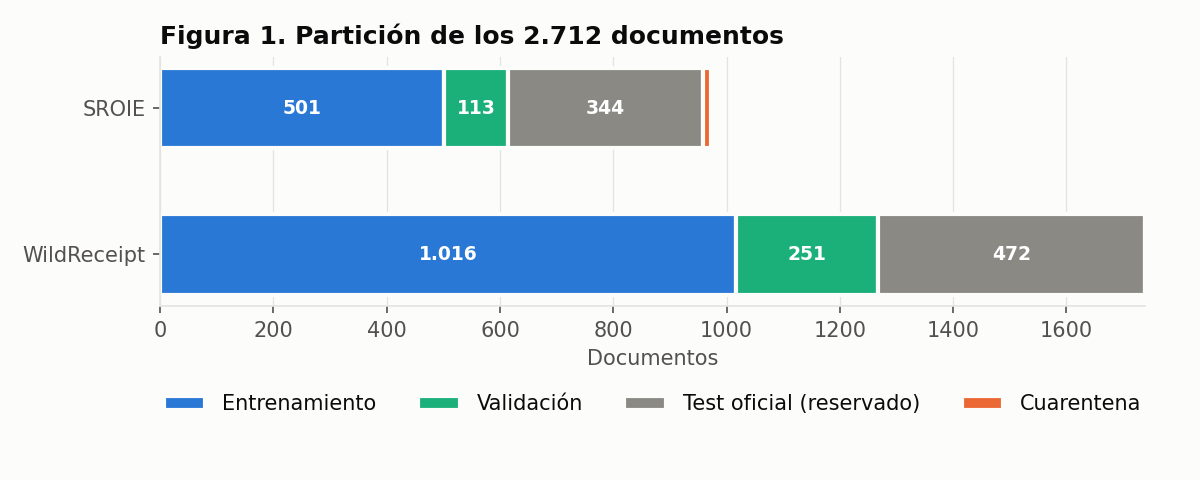

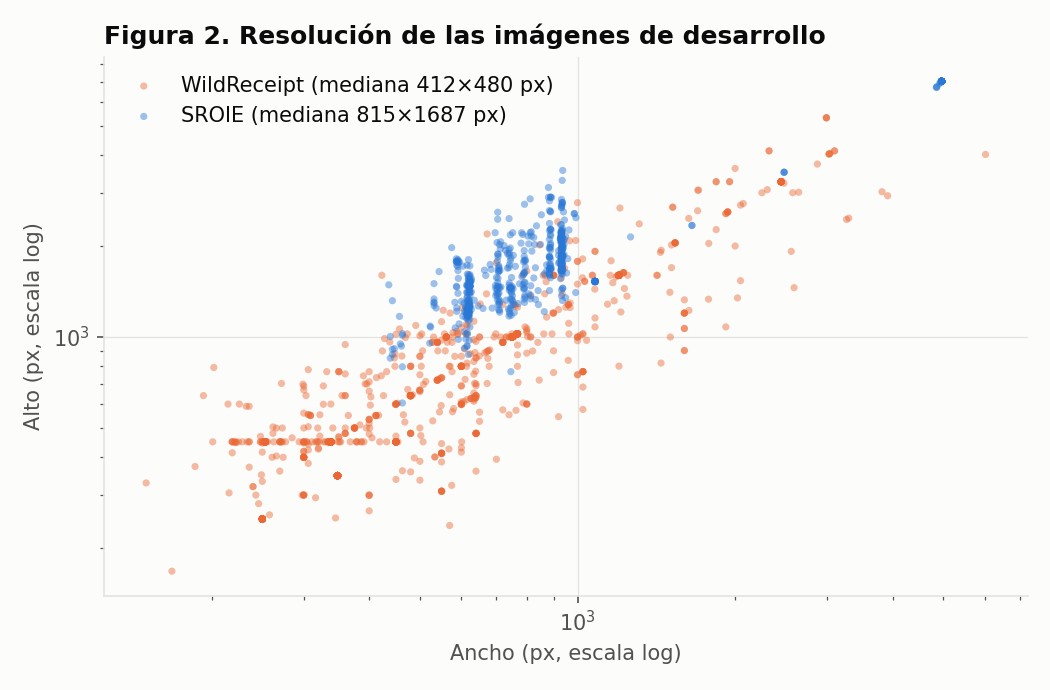

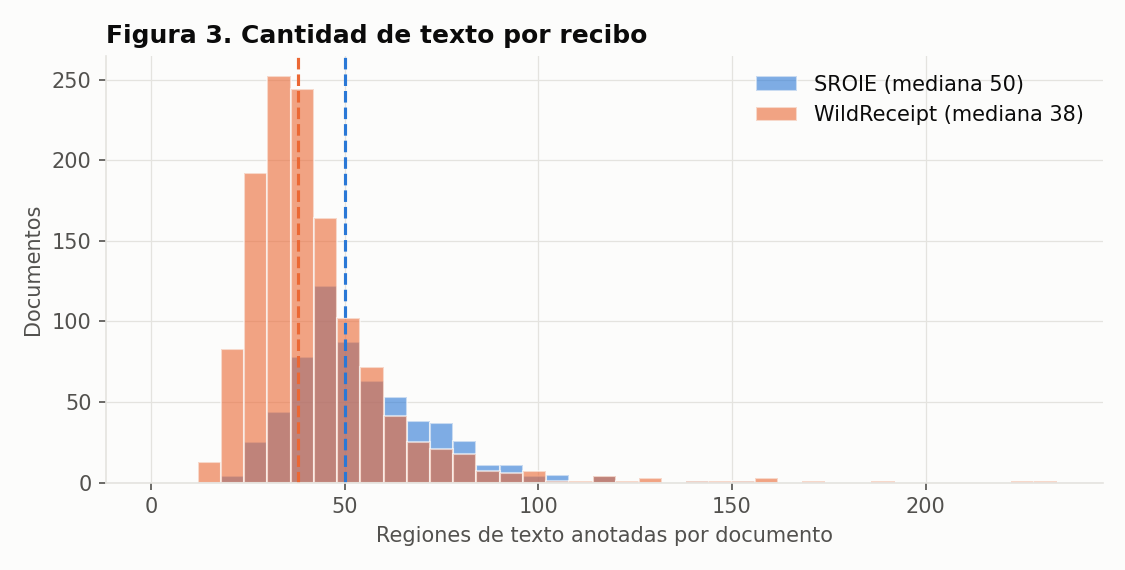

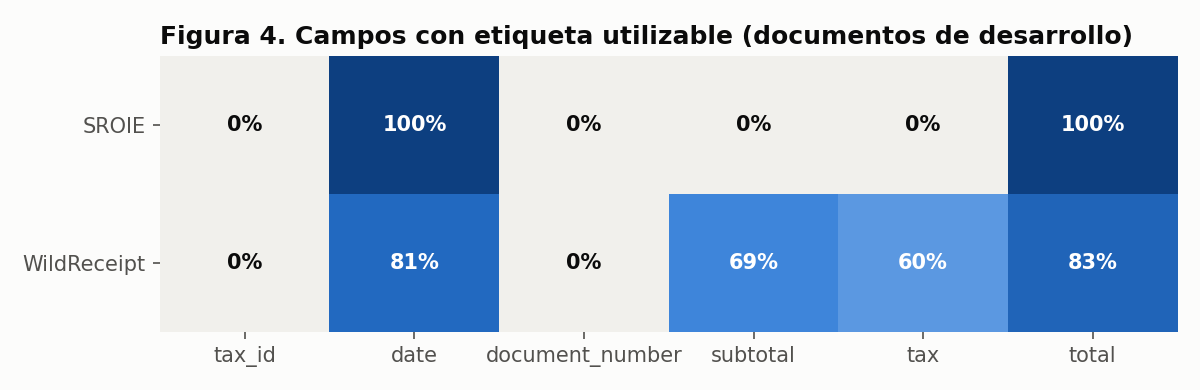

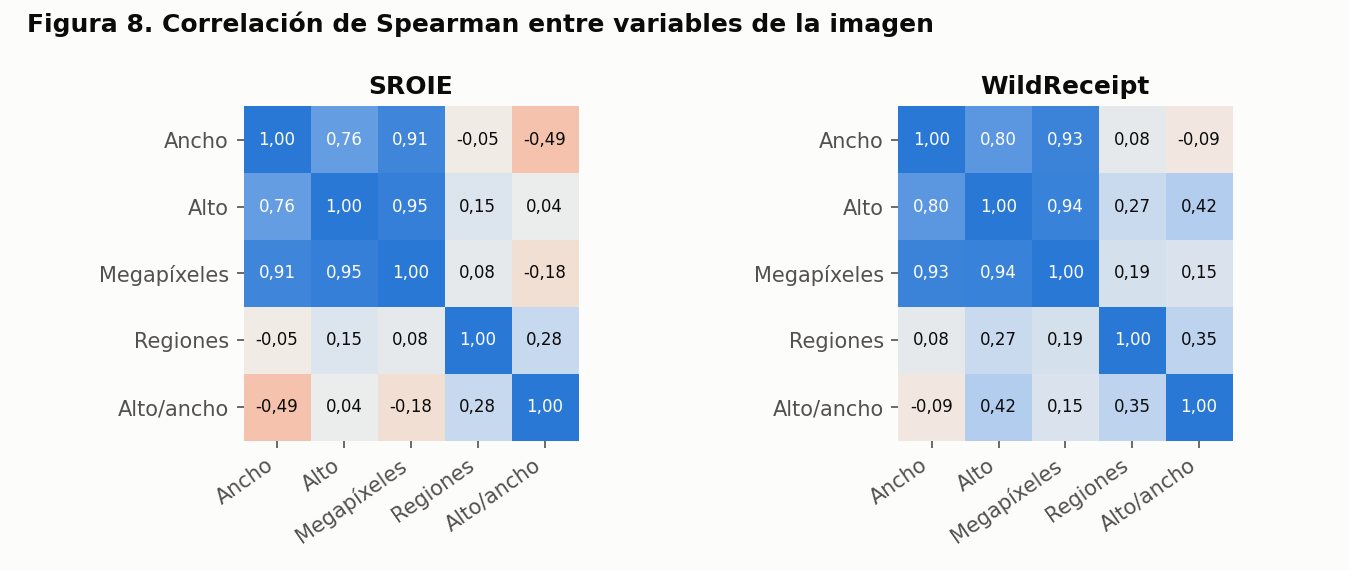

In [12]:
F.fig_particiones(documentos, incidencias, manifest, FIG)
F.fig_resolucion(documentos, FIG)
F.fig_regiones(documentos, FIG)
F.fig_cobertura(cobertura, FIG)
matrices = F.fig_correlaciones(documentos, FIG)
for nombre in ['01_particiones', '02_resolucion', '03_regiones', '04_cobertura', '08_correlaciones']:
    display(Img(filename=str(FIG / f'{nombre}.png')))

### 6.1 Correlaciones
Spearman (por rangos) porque las variables de tamaño son muy asimétricas.

In [13]:
for base, m in matrices.items():
    display(Markdown(f'**{F.NOMBRE[base]}**'))
    display(m.round(2))

**SROIE**

,width,height,mpx,regions,aspect
width,1.00,0.76,0.91,-0.05,-0.49
height,0.76,1.00,0.95,0.15,0.04
mpx,0.91,0.95,1.00,0.08,-0.18
regions,-0.05,0.15,0.08,1.00,0.28
aspect,-0.49,0.04,-0.18,0.28,1.00


**WildReceipt**

,width,height,mpx,regions,aspect
width,1.00,0.80,0.93,0.08,-0.09
height,0.80,1.00,0.94,0.27,0.42
mpx,0.93,0.94,1.00,0.19,0.15
regions,0.08,0.27,0.19,1.00,0.35
aspect,-0.09,0.42,0.15,0.35,1.00


## 7. Patrones en las etiquetas
### 7.1 Formatos de fecha
Cuántos formatos distintos aparecen en las fechas de referencia y cuántas son ambiguas (día y mes ≤ 12, sin que se pueda saber cuál es cuál).

In [14]:
desarrollo = [r for r in FILAS if r['split'] in ('train', 'validation')]
filas_fecha = []
for r in desarrollo:
    oro = r['gold']['date']
    if oro['status'] != 'annotated':
        continue
    valor = str(oro['value']).strip()
    m = re.fullmatch(r'\(?(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})\)?', valor)
    ambigua = bool(m and int(m.group(1)) <= 12 and int(m.group(2)) <= 12 and m.group(1) != m.group(2))
    filas_fecha.append({'dataset': r['dataset'], 'fecha': valor, 'patron': F.patron(valor), 'ambigua': ambigua,
                        'normalizada': normalize('date', valor, CONFIG['normalization'])})
fechas = pd.DataFrame(filas_fecha)
resumen_fechas = fechas.groupby('dataset').agg(fechas=('fecha', 'size'), formatos=('patron', 'nunique'),
                                               ambiguas=('ambigua', 'sum'))
resumen_fechas['% ambiguas'] = (100 * resumen_fechas.ambiguas / resumen_fechas.fechas).round(1)
resumen_fechas['% sin normalizar'] = fechas.groupby('dataset').normalizada.apply(
    lambda s: round(100 * s.str.startswith('RAW:').mean(), 1))
display(resumen_fechas)
for base, g in fechas.groupby('dataset'):
    top = g.patron.value_counts().head(8)
    display(Markdown(f'**{F.NOMBRE[base]}: formatos más frecuentes**'))
    display(pd.DataFrame({'documentos': top, 'ejemplo': [g[g.patron == p].fecha.iloc[0] for p in top.index]}))

,fechas,formatos,ambiguas,% ambiguas,% sin normalizar
dataset,,,,,
sroie,614,17,201,32.7,0.5
wildreceipt,1025,92,278,27.1,4.6


**SROIE: formatos más frecuentes**

,documentos,ejemplo
patron,,
99/99/9999,321,25/12/2018
99-99-99,81,12-01-19
99-99-9999,70,23-01-2019
99/99/99,61,18/03/18
99 A 9999,47,05 MAR 2018
9/9/9999,6,5/3/2018
99 A 99,5,28 MAR 18
9999-99-99,4,2018-03-23


**WildReceipt: formatos más frecuentes**

,documentos,ejemplo
patron,,
99/99/9999,314,01/14/2012
99/99/99,181,12/22/17
9/99/9999,58,7/18/2016
A99'99,52,Nov26'09
99-99-9999,49,11-14-2016
99A'99,34,14Jan'18
9999-99-99,28,2004-10-31
9/99/99,27,7/18/12


### 7.2 Montos: tasa de impuesto y cuadre
En WildReceipt (único dataset con subtotal e impuesto) revisamos la relación impuesto/subtotal y si se cumple **subtotal + impuesto = total**. Esto justifica dos reglas del extractor: la búsqueda de tres montos que cuadran en una fila y el filtro de razón impuesto/subtotal entre 0,02 y 0,30.

Recibos con los tres montos anotados: 571
Cuadran (subtotal + impuesto = total, ±0,02): 460 (80.6 %)
Razón impuesto/subtotal entre 0,02 y 0,30: 473 (82.8 %)


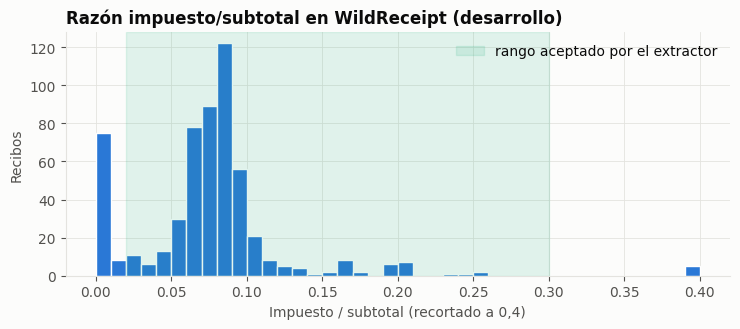

In [15]:
from decimal import Decimal
from lector_facturas.common import money

montos = []
for r in desarrollo:
    if r['dataset'] != 'wildreceipt':
        continue
    g = r['gold']
    valores = {c: money(g[c]['value']) if g[c]['status'] == 'annotated' else None for c in ('subtotal', 'tax', 'total')}
    if all(valores.values()):
        s, t, tot = (Decimal(valores[c]) for c in ('subtotal', 'tax', 'total'))
        montos.append({'id': r['id'], 'subtotal': float(s), 'tax': float(t), 'total': float(tot),
                       'razon': float(t / s) if s else np.nan, 'cuadra': abs(s + t - tot) <= Decimal('0.02')})
montos = pd.DataFrame(montos)
if not montos.empty:
    print(f'Recibos con los tres montos anotados: {len(montos)}')
    print(f'Cuadran (subtotal + impuesto = total, ±0,02): {montos.cuadra.sum()} ({100 * montos.cuadra.mean():.1f} %)')
    dentro = montos.razon.between(0.02, 0.30)
    print(f'Razón impuesto/subtotal entre 0,02 y 0,30: {dentro.sum()} ({100 * dentro.mean():.1f} %)')
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.hist(montos.razon.clip(0, 0.4), bins=40, color=F.AZUL, edgecolor='white')
    ax.axvspan(0.02, 0.30, color=F.AQUA, alpha=.12, label='rango aceptado por el extractor')
    ax.set_xlabel('Impuesto / subtotal (recortado a 0,4)'); ax.set_ylabel('Recibos')
    ax.set_title('Razón impuesto/subtotal en WildReceipt (desarrollo)', loc='left'); ax.legend()
    plt.tight_layout(); fig.savefig(FIG / '10_razon_impuesto.png', dpi=150); plt.show()
else:
    print('WildReceipt no está disponible; se omite este análisis.')

### 7.3 Posición de cada campo en el recibo
Con las cajas etiquetadas de WildReceipt calculamos dónde aparece cada campo (posición vertical normalizada: 0 = arriba, 1 = abajo). Esto respalda usar la geometría (líneas, cercanía a la etiqueta, tramo inferior del recibo) en el extractor.

y                                                 x                                          
           count  mean   std   min   25%   50%   75%   max   count  mean   std   min   25%   50%   75%   max
campo                                                                                                       
date      1204.0  0.41  0.24  0.02  0.24  0.35  0.53  0.99  1204.0  0.42  0.18  0.05  0.28  0.40  0.55  0.85
subtotal   966.0  0.63  0.16  0.05  0.52  0.64  0.74  0.98   966.0  0.73  0.13  0.11  0.68  0.75  0.81  0.95
tax       1030.0  0.67  0.16  0.07  0.56  0.67  0.78  0.99  1030.0  0.73  0.12  0.20  0.67  0.74  0.82  0.95
total     1524.0  0.69  0.16  0.13  0.58  0.70  0.82  0.98  1524.0  0.73  0.10  0.16  0.67  0.74  0.80  0.98

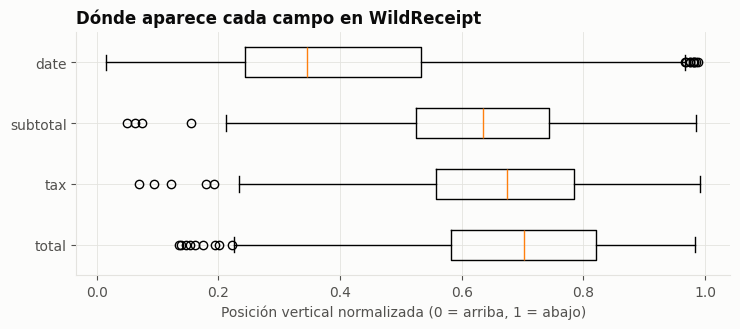

In [16]:
posiciones = []
for r in desarrollo:
    if r['dataset'] != 'wildreceipt' or not r.get('height'):
        continue
    for region in r['regions']:
        campo = ETIQUETA_WILD.get(region.get('label'))
        if campo:
            x1, y1, x2, y2 = region['box']
            posiciones.append({'campo': campo, 'y': (y1 + y2) / 2 / r['height'], 'x': (x1 + x2) / 2 / r['width']})
posiciones = pd.DataFrame(posiciones)
if not posiciones.empty:
    orden = ['date', 'subtotal', 'tax', 'total']
    display(posiciones.groupby('campo')[['y', 'x']].describe(percentiles=[.25, .5, .75]).loc[orden].round(2))
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.boxplot([posiciones[posiciones.campo == c].y for c in orden], vert=False, widths=.5)
    ax.set_yticks(range(1, len(orden) + 1), orden)
    ax.set_xlabel('Posición vertical normalizada (0 = arriba, 1 = abajo)'); ax.invert_yaxis()
    ax.set_title('Dónde aparece cada campo en WildReceipt', loc='left')
    plt.tight_layout(); fig.savefig(FIG / '11_posicion_campos.png', dpi=150); plt.show()
else:
    print('WildReceipt no está disponible; se omite este análisis.')

## 8. Outliers e incidencias
Outliers por el criterio de 1,5 × IQR. No se eliminan: son documentos reales que el sistema debe poder leer.

In [17]:
descriptivas_csv, outliers = F.tablas(documentos, FIG)
display(outliers)
display(Markdown('**Documentos más grandes y más pequeños (megapíxeles)**'))
display(pd.concat([documentos.nlargest(3, 'mpx'), documentos.nsmallest(3, 'mpx')])[['id', 'dataset', 'width', 'height', 'mpx', 'regions']].round(2))
display(Markdown('**Incidencias por tipo**'))
display(incidencias.groupby(['dataset', 'issue']).size().rename('documentos').reset_index())

  tablas: estadisticas_descriptivas.csv, outliers_iqr.csv


,dataset,variable,outliers,documentos,porcentaje,limite_inferior,limite_superior
0,sroie,width,86,614,14.0,153.50,1405.50
1,sroie,height,86,614,14.0,283.00,3259.00
2,sroie,mpx,86,614,14.0,-0.60,3.48
3,sroie,regions,15,614,2.4,10.50,94.50
4,wildreceipt,width,98,1267,7.7,-280.00,1368.00
5,wildreceipt,height,89,1267,7.0,-375.00,1825.00
6,wildreceipt,mpx,152,1267,12.0,-0.75,1.65
7,wildreceipt,regions,65,1267,5.1,3.00,75.00


**Documentos más grandes y más pequeños (megapíxeles)**

,id,dataset,width,height,mpx,regions
274,sroie/train/X51006414394,sroie,4961,7016,34.81,76
275,sroie/train/X51006414429,sroie,4961,7016,34.81,39
276,sroie/train/X51006414431,sroie,4961,7016,34.81,35
898,wildreceipt/train/image_files/Image_56/2/f820a...,wildreceipt,168,168,0.03,50
1170,wildreceipt/train/image_files/Image_27/14/2831...,wildreceipt,150,329,0.05,72
647,wildreceipt/train/image_files/Image_79/7/3960....,wildreceipt,250,250,0.06,28


**Incidencias por tipo**

,dataset,issue,documentos
0,sroie,duplicate_image_hash,15
1,sroie,duplicate_in_official_test,7
2,sroie,encoding_fallback_cp1252,1
3,sroie,invalid_box,1
4,sroie,invalid_box_line,1
5,wildreceipt,annotation_dimensions_mismatch,16
6,wildreceipt,invalid_box,1


## 9. Conclusiones
Las cifras exactas son las que imprime este notebook; las de la ejecución documentada están en `docs/analisis_datos.md`.

1. **Cobertura de etiquetas.** SROIE solo permite evaluar fecha y total; WildReceipt añade subtotal e impuesto. Ningún dataset anota `tax_id` ni `document_number`, que quedan para la muestra propia. Los campos sin etiqueta no se cuentan como error.
2. **Resolución muy desigual.** Las fotos de WildReceipt son mucho más pequeñas que los escaneos de SROIE → el preprocesamiento amplía las imágenes y limita el tamaño máximo (notebook 02).
3. **Texto de relleno.** Un recibo tiene decenas de regiones y solo unas pocas son campos útiles → las métricas se reportan por campo y no con accuracy global.
4. **Fechas ambiguas y en muchos formatos** → el normalizador no adivina el orden día/mes.
5. **Montos que cuadran y tasas de impuesto acotadas** → reglas aritméticas en el extractor (notebook 03).
6. **Outliers reales** → se conservan y se controlan con el tope de píxeles.
7. **Sin fugas** entre train, validation y test (comprobado por hash).

In [ ]:
# Descargar las figuras en un ZIP.
archivo = SALIDAS / 'figuras_eda.zip'
with zipfile.ZipFile(archivo, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FIG.glob('*')):
        z.write(p, p.name)
print('ZIP:', archivo)
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    pass